# Variational optimization of finite PEPS with boundary MPS
We find the ground state of the two-dimensional transverse field Ising model with a projected entangled pair state (PEPS) on a finite $L_x \times L_y$ lattice with open boundaries. The PEPS assigns a tensor $A_{(x,y)}$ with a physical index and four virtual indices of bond dimension $D$ to every site.

The tensors are optimized one at a time, while all others are kept fixed [Verstraete & Cirac, cond-mat/0407066]. The energy
$$
E = \frac{\langle\psi|H|\psi\rangle}{\langle\psi|\psi\rangle} = \frac{A^\dagger H_\text{eff} A}{A^\dagger N_\text{eff} A}
$$
is a ratio of two quadratic forms in the elements of the tensor $A$ of one site, so its minimum is the lowest solution of the generalized eigenvalue problem (GEP) $H_\text{eff} A = E N_\text{eff} A$. The effective norm $N_\text{eff}$ and the effective Hamiltonian $H_\text{eff}$ are the networks $\langle\psi|\psi\rangle$ and $\langle\psi|H|\psi\rangle$ with the tensor of the site and its complex conjugate cut out. They cannot be contracted exactly for large lattices; we approximate them with **boundary MPS** of bond dimension $\chi$.

We keep the terms of the Hamiltonian separate and do not combine them into a projected entangled pair operator (PEPO): $H_\text{eff} = \sum_t H_\text{eff}^{(t)}$ is the sum of the effective Hamiltonians of all terms $h_t$, and every term gets its own boundary MPS [Verstraete & Cirac; Isacsson & Syljuåsen, cond-mat/0604134].

Contents:
1. Model and exact diagonalization for small lattices
2. PEPS
3. Boundary MPS, row strips and expectation values
4. Effective Hamiltonian from separate terms
5. The generalized eigenvalue problem
6. Sweeps, tests and the growth of the bond dimension
7. Results: dependence on $D$, $\chi$ and the system size $V = L \times L$
8. Damped updates: optimization with truncated boundaries

## Install
Import Cytnx, see https://cytnx-dev.github.io/Cytnx/

In [1]:
# The following 2 lines are only needed if you installed Cytnx from source
import sys
sys.path.insert(0,'/home/manuel/Cytnx_lib') # change to your installation path

# The tensors in this notebook are small, so multithreading only adds overhead, and idle
# OpenMP threads should sleep instead of spinning. Both must be set before cytnx is imported.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OMP_WAIT_POLICY"] = "PASSIVE"

import cytnx
import math
import time
import matplotlib.pyplot as plt
print(cytnx.__version__)

1.1.1


## 1. Model
The transverse field Ising model on an $L_x \times L_y$ square lattice with open boundaries,
$$
H = -J \sum_{\langle i,j \rangle} \sigma^z_i \sigma^z_j - h \sum_i \sigma^x_i ,
$$
has a quantum phase transition at $h_c \approx 3.044\,J$ in the thermodynamic limit, between the ordered phase ($h < h_c$) and the paramagnetic phase ($h > h_c$). We use $J = 1$ and a field close to the critical point, $h = 3.04$, as well as $h = 2$ in the ordered phase.

Every term is a product of single-site operators: $\sigma^z \sigma^z$ on a nearest-neighbor bond, $\sigma^x$ on a site. We store the Hamiltonian as a list of terms `(coefficient, {site: operator})`; all algorithms below only use this list.

In [2]:
def pauli(name):
    if name == "x":
        return cytnx.physics.pauli("x").real()
    if name == "z":
        return cytnx.physics.pauli("z").real()
    if name == "1":
        return cytnx.eye(2)
    raise ValueError(name)

def ising_terms(Lx, Ly, J, h):
    """List of terms (coefficient, {(x, y): operator name}); each term is a product of
    single-site operators."""
    terms = []
    for y in range(Ly):
        for x in range(Lx):
            if x + 1 < Lx:
                terms.append((-J, {(x, y): "z", (x + 1, y): "z"}))
            if y + 1 < Ly:
                terms.append((-J, {(x, y): "z", (x, y + 1): "z"}))
            terms.append((-h, {(x, y): "x"}))
    return terms

In [3]:
J = 1.0
h = 3.04
terms = ising_terms(3, 3, J, h)
print(len(terms), "terms on a 3 x 3 lattice, e.g.", terms[:3])

21 terms on a 3 x 3 lattice, e.g. [(-1.0, {(0, 0): 'z', (1, 0): 'z'}), (-1.0, {(0, 0): 'z', (0, 1): 'z'}), (-3.04, {(0, 0): 'x'})]


### Exact diagonalization
For lattices up to $4 \times 4$ we can compute the exact ground state energy with the Lanczos method. `IsingOp` applies $H$ to a state vector of length $2^V$: the $\sigma^z\sigma^z$ terms are diagonal in the $\sigma^z$ basis and summed once in the constructor, a $\sigma^x$ term flips one spin.

In [4]:
class IsingOp(cytnx.LinOp):
    """H acting on a state vector psi of length 2^V (V = Lx * Ly). Site (x, y) has the
    index i = x + Lx * y and is the i-th most significant bit of the basis state.

    Terms that consist of sz only are diagonal; their sum is computed once. A term sx_i
    flips bit i: reshaped to (2^i, 2, 2^(V-1-i)), psi is multiplied by sx on the middle
    index."""

    def __init__(self, Lx, Ly, terms):
        V = Lx * Ly
        cytnx.LinOp.__init__(self, "mv", 2 ** V)
        self.V = V
        self.diagonal = cytnx.zeros(2 ** V)
        self.flips = []
        for c, ops in terms:
            if all(o == "z" for o in ops.values()):
                v = cytnx.ones(1)
                for i in range(V):
                    d = cytnx.ones(2)
                    if ops.get((i % Lx, i // Lx)) == "z":
                        d[1] = -1
                    v = cytnx.linalg.Kron(v, d)
                self.diagonal += c * v
            elif len(ops) == 1 and list(ops.values())[0] == "x":
                (x, y), = ops.keys()
                self.flips.append((c, x + Lx * y))
            else:
                raise ValueError("only products of sz and single sx terms are implemented")
        self.sx = pauli("x")

    def matvec(self, psi):
        out = self.diagonal * psi
        for c, i in self.flips:
            psi3 = psi.reshape(2 ** i, 2, 2 ** (self.V - 1 - i))
            flipped = cytnx.linalg.Tensordot(psi3, self.sx, [1], [0]).permute(0, 2, 1).contiguous()
            out += c * flipped.reshape(2 ** self.V)
        return out

def exact_ground_state(Lx, Ly, terms):
    """Ground state energy and vector by Lanczos (ARPACK); feasible up to about 4 x 4."""
    Hop = IsingOp(Lx, Ly, terms)
    psi = cytnx.random.uniform(2 ** (Lx * Ly), -1, 1, seed=0)
    E, psi0 = cytnx.linalg.Lanczos(Hop, psi, which="SA", Maxiter=10000, CvgCrit=1e-12, k=1, is_V=True)
    return E[0].item(), psi0

def dense_energy(psi, Lx, Ly, terms):
    """<psi|H|psi> / <psi|psi> for a state vector psi."""
    Hpsi = IsingOp(Lx, Ly, terms).matvec(psi)
    return cytnx.linalg.Vectordot(psi, Hpsi).item() / cytnx.linalg.Vectordot(psi, psi).item()

In [5]:
exact = {}
for h_ in [3.04, 2.0]:
    for L in [3, 4]:
        start = time.perf_counter()
        exact[(h_, L)] = exact_ground_state(L, L, ising_terms(L, L, J, h_))[0]
        print("h = %.2f, %d x %d: E0 = %.10f, E0/V = %.10f  (%.1f s)"
              % (h_, L, L, exact[(h_, L)], exact[(h_, L)] / L**2, time.perf_counter() - start))

h = 3.04, 3 x 3: E0 = -28.4178929867, E0/V = -3.1575436652  (0.0 s)


h = 3.04, 4 x 4: E0 = -50.7918328340, E0/V = -3.1744895521  (1.5 s)
h = 2.00, 3 x 3: E0 = -19.7941363349, E0/V = -2.1993484817  (0.0 s)


h = 2.00, 4 x 4: E0 = -35.9072576204, E0/V = -2.2442036013  (1.7 s)


## 2. PEPS
The tensor of site $(x, y)$ has five legs; $x$ counts the columns from the left, $y$ the rows from the top:
```
                kv(x,y)
                   |
     kh(x,y) ---- A(x,y) ---- kh(x+1,y)
                   |   \
               kv(x,y+1)  p(x,y)
```
As in the previous notebooks, the labels are global: a virtual bond has the same label in both tensors it connects, so `Contract` connects the right legs. `kh(x,y)` is the horizontal bond between $(x-1,y)$ and $(x,y)$, `kv(x,y)` the vertical bond between $(x,y-1)$ and $(x,y)$. Legs at the boundary of the lattice have dimension 1. The bonds are directed: left, up and physical legs are incoming, right and down legs are outgoing.

The bra tensor is the complex conjugate: `Dagger` conjugates and flips the directions, and its virtual legs get the labels `bh`, `bv` instead of `kh`, `kv`. The physical legs of ket and bra keep the same label, so contracting them gives $\langle\psi|\psi\rangle$. To insert a single-site operator, we apply it to the ket tensor.

The initial state is the product state with all spins in the $x$ direction plus random noise; the noise breaks the symmetry, so the optimization can leave this saddle point. Later, `grow_bond_dimension` embeds the tensors in tensors with a larger $D$, plus random noise.

In [6]:
def kh(x, y): return f"kh{x}_{y}"

def kv(x, y): return f"kv{x}_{y}"

def bh(x, y): return f"bh{x}_{y}"

def bv(x, y): return f"bv{x}_{y}"

def phys(x, y): return f"p{x}_{y}"

class PEPS:
    """Finite PEPS on an Lx x Ly lattice with open boundaries.

    The tensor of site (x, y) has the legs kh(x,y) (left, incoming), kh(x+1,y) (right,
    outgoing), kv(x,y) (up, incoming), kv(x,y+1) (down, outgoing) and phys(x,y)
    (incoming). Legs at the lattice boundary have dimension 1."""

    def __init__(self, Lx, Ly, D, d=2):
        self.Lx, self.Ly, self.D, self.d = Lx, Ly, D, d
        self.A = {}
        self.bra_cache = {}

    def dims(self, x, y, D=None):
        D = self.D if D is None else D
        return [1 if x == 0 else D, 1 if x == self.Lx - 1 else D,
                1 if y == 0 else D, 1 if y == self.Ly - 1 else D, self.d]

    def labels(self, x, y):
        return [kh(x, y), kh(x + 1, y), kv(x, y), kv(x, y + 1), phys(x, y)]

    def set_tensor(self, x, y, data):
        """Set the tensor of site (x, y) from a Tensor of shape (left, right, up, down, d)."""
        Dl, Dr, Du, Dd, d = data.shape()
        bonds = [cytnx.Bond(Dl, cytnx.BD_KET), cytnx.Bond(Dr, cytnx.BD_BRA),
                 cytnx.Bond(Du, cytnx.BD_KET), cytnx.Bond(Dd, cytnx.BD_BRA), cytnx.Bond(d, cytnx.BD_KET)]
        A = cytnx.UniTensor(bonds, labels=self.labels(x, y), rowrank=4, dtype=data.dtype())
        A.put_block(data.contiguous())
        self.A[(x, y)] = A
        self.bra_cache.pop((x, y), None)

    def data(self, x, y):
        return self.A[(x, y)].permute(self.labels(x, y)).get_block().contiguous()

    def ket(self, x, y, op=None):
        """Ket tensor of site (x, y), with the single-site operator `op` applied if given."""
        A = self.A[(x, y)]
        if op is None:
            return A
        return cytnx.Contract(site_op(op, x, y), A).relabel(phys(x, y) + "'", phys(x, y))

    def bra(self, x, y):
        """Complex conjugate of the ket tensor; its virtual legs carry the bra labels."""
        if (x, y) not in self.bra_cache:
            old = [kh(x, y), kh(x + 1, y), kv(x, y), kv(x, y + 1)]
            new = [bh(x, y), bh(x + 1, y), bv(x, y), bv(x, y + 1)]
            self.bra_cache[(x, y)] = self.A[(x, y)].Dagger().relabel(old, new)
        return self.bra_cache[(x, y)]

def site_op(name, x, y):
    """Single-site operator with legs phys(x,y)' (incoming) and phys(x,y) (outgoing)."""
    O = cytnx.UniTensor([cytnx.Bond(2, cytnx.BD_KET), cytnx.Bond(2, cytnx.BD_BRA)],
                        labels=[phys(x, y) + "'", phys(x, y)], rowrank=1)
    O.put_block(pauli(name))
    return O

def product_peps(Lx, Ly, state, noise=0.0, seed=0):
    """D = 1 PEPS of the product state `state` (a list of d amplitudes) plus random noise."""
    peps = PEPS(Lx, Ly, 1, len(state))
    for y in range(Ly):
        for x in range(Lx):
            data = cytnx.zeros([1, 1, 1, 1, len(state)])
            for s, a in enumerate(state):
                data[0, 0, 0, 0, s] = a
            if noise > 0:
                data += noise * cytnx.random.uniform([1, 1, 1, 1, len(state)], -1, 1, seed=seed + x + Lx * y)
            peps.set_tensor(x, y, data / data.norm())
    return peps

def grow_bond_dimension(peps, D, noise=0.1, seed=1):
    """Return a PEPS with bond dimension D > peps.D: the old tensors are embedded in the
    larger ones, and all entries get random noise of relative size `noise`."""
    new = PEPS(peps.Lx, peps.Ly, D, peps.d)
    for (x, y), A in peps.A.items():
        old = peps.data(x, y)
        data = noise * cytnx.random.uniform(new.dims(x, y), -1, 1, seed=seed + x + peps.Lx * y)
        Dl, Dr, Du, Dd, d = old.shape()
        data[:Dl, :Dr, :Du, :Dd, :] += old
        new.set_tensor(x, y, data / data.norm())
    return new

def copy_peps(peps):
    new = PEPS(peps.Lx, peps.Ly, peps.D, peps.d)
    new.A = {site: A.clone() for site, A in peps.A.items()}
    return new

def peps_to_state(peps):
    """Contract all ket tensors (exponential cost; only for tests on small lattices)."""
    psi = None
    for y in range(peps.Ly):
        for x in range(peps.Lx):
            psi = peps.ket(x, y) if psi is None else cytnx.Contract(psi, peps.ket(x, y))
    labels = [phys(x, y) for y in range(peps.Ly) for x in range(peps.Lx)]
    rest = [l for l in psi.labels() if l not in labels]
    return psi.permute(labels + rest).get_block().contiguous().reshape(2 ** len(labels))

## 3. Boundary MPS
The norm $\langle\psi|\psi\rangle$ is a two-layer network: every ket tensor is connected to its bra tensor by the physical index. We contract it row by row. A **top boundary MPS** approximates all rows above row $r$; its tensor in column $x$ has two chain legs (bond dimension at most $\chi$) and two legs that connect to the up legs of the ket and of the bra tensor of $(x, r)$:
```
   T0 -- T(0) -- T1 -- T(1) -- T2 -- ...        chain legs: bond dimension <= chi
         |   \         |   \
      kv(0,r) bv(0,r)  ...                      ket and bra legs kept separate
```
Keeping the ket and bra legs separate (instead of one combined leg of dimension $D^2$) allows to contract the ket and the bra layer one after the other, which is cheaper. Bottom boundaries are defined in the same way for the rows below row $r$.

We start with a trivial boundary outside the lattice: all tensors are the number 1 and all legs have dimension 1. Then every step is the same: **absorb** the next row into the boundary. The exact result $v$ (old boundary, ket row, bra row) has chain bonds of dimension $\chi D^2$; we approximate it by a new boundary $w$ with bond dimension $\chi$. As in `apply_mpo` of the time evolution notebook, we find $w$ by a variational two-site fit: sweeping from left to right and back, each pair of neighboring tensors of $w$ is set to the optimal two-site tensor (the network $v$ contracted with the rest of $w$, in mixed canonical form) and split by a truncated SVD. The fit stops when $f = |\langle w|v\rangle| / \|w\|$ is converged. Note that `Svd_truncate(T, keepdim, err)` drops singular values smaller than `err` in absolute terms; since the two-site tensor shrinks with the norm of the network, we normalize it before the SVD (`truncated_svd`). Without this, an "exact" boundary was silently truncated at a relative level of $10^{-7}$ and worse on larger lattices. The boundary is normalized after each step; its norm is kept as a logarithm, because the norm of a PEPS can grow or shrink exponentially with the system size.

`absorb_row` can apply single-site operators to the kets of the absorbed row. We need this for the Hamiltonian terms in section 4.

In [7]:
class Boundary:
    """Boundary MPS that approximates the ket-bra network of the rows above (side "top")
    or below (side "bottom") row `row`.

    tensors[x] has the chain legs prefix+x and prefix+(x+1) and two legs that connect to
    the ket and bra tensors of row `row`: the up legs kv(x,row), bv(x,row) for a top
    boundary, the down legs kv(x,row+1), bv(x,row+1) for a bottom boundary. The boundary
    is normalized; its norm is kept as exp(lognorm)."""

    def __init__(self, side, row, tensors, lognorm=0.0):
        self.side, self.row, self.tensors, self.lognorm = side, row, tensors, lognorm
        self.prefix = "T" if side == "top" else "B"

def vertical_legs(side, x, row):
    """Labels of the ket and bra legs of row `row` that a boundary of this side attaches to."""
    y = row if side == "top" else row + 1
    return kv(x, y), bv(x, y)

def trivial_boundary(peps, side):
    """Boundary outside the lattice: every tensor is the number 1, all legs have dimension 1."""
    row = 0 if side == "top" else peps.Ly - 1
    prefix = "T" if side == "top" else "B"
    tensors = []
    for x in range(peps.Lx):
        lk, lb = vertical_legs(side, x, row)
        bonds = [cytnx.Bond(1, cytnx.BD_KET), cytnx.Bond(1, cytnx.BD_BRA),
                 peps.ket(x, row).bond(lk).redirect(), peps.bra(x, row).bond(lb).redirect()]
        T = cytnx.UniTensor(bonds, labels=[f"{prefix}{x}", f"{prefix}{x+1}", lk, lb], rowrank=2)
        T.at([0, 0, 0, 0]).value = 1
        tensors.append(T)
    return Boundary(side, row, tensors)

def trivial_env(*legs):
    """Environment of dimension 1 that closes the given (tensor, label) legs."""
    bonds = [T.bond(label).redirect() for T, label in legs]
    E = cytnx.UniTensor(bonds, labels=[label for _, label in legs], rowrank=len(bonds))
    E.at([0] * len(bonds)).value = 1
    return E

def right_canonical(w, prefix):
    """Bring the MPS w (chain legs prefix+x) into right-canonical form and normalize it."""
    L = len(w)
    for x in range(L - 1, 0, -1):
        others = [l for l in w[x].labels() if l != f"{prefix}{x}"]
        T = w[x].permute([f"{prefix}{x}"] + others, rowrank=1)
        S, U, V = cytnx.linalg.Svd(T)
        w[x] = V.relabel("_aux_R", f"{prefix}{x}")
        w[x - 1] = cytnx.Contract(w[x - 1], cytnx.Contract(U, S)).relabel("_aux_R", f"{prefix}{x}")
    w[0] = w[0] / w[0].norm()
    return w

def truncated_svd(T, chi, err=1e-14):
    """SVD keeping at most chi singular values and dropping those below err relative to the
    norm of T. Svd_truncate compares the singular values with err directly, so T is
    normalized first and S is scaled back afterwards."""
    norm = T.norm()
    S, U, V = cytnx.linalg.Svd_truncate(T / norm, keepdim=chi, err=err)
    return S * norm, U, V

def absorb_row(boundary, peps, ops, chi, guess=None, maxit=10, tol=1e-10):
    """Add the row next to `boundary` (ket and bra layer, with the single-site operators
    ops = {(x, y): name} applied to the ket layer) and approximate the result by a new
    boundary MPS with bond dimension chi.

    The new boundary w is found by a two-site variational fit of the network v = (old
    boundary, ket row, bra row), sweeping from left to right and back, like apply_mpo in
    the time evolution notebook. The fit stops after `maxit` iterations (one right and one
    left sweep each) or when f = |<w|v>| / |w| changes by at most tol between two half
    sweeps. `guess` is an initial boundary (e.g. from the previous sweep), else w starts
    random."""
    side, r, P = boundary.side, boundary.row, boundary.prefix
    Lx = peps.Lx
    new_row = r + 1 if side == "top" else r - 1
    old = boundary.tensors
    K = [peps.ket(x, r, ops.get((x, r))) for x in range(Lx)]
    Br = [peps.bra(x, r) for x in range(Lx)]
    out = [vertical_legs(side, x, new_row) for x in range(Lx)]   # open legs of the new boundary

    # ---- initial guess w (chain legs N0..N{Lx}) in right-canonical form
    w = None
    if guess is not None:
        w = [T.relabel([f"{P}{x}", f"{P}{x+1}"], [f"N{x}", f"N{x+1}"]) for x, T in enumerate(guess.tensors)]
        if any(w[x].bond(out[x][0]).dim() != K[x].bond(out[x][0]).dim() for x in range(Lx)):
            w = None   # bond dimension of the PEPS changed
    if w is None:
        phys_dims = [K[x].bond(out[x][0]).dim() * Br[x].bond(out[x][1]).dim() for x in range(Lx)]
        chain = [1]
        for x in range(1, Lx):
            chain.append(min(chi, math.prod(phys_dims[:x]), math.prod(phys_dims[x:])))
        chain.append(1)
        w = []
        for x in range(Lx):
            bonds = [cytnx.Bond(chain[x], cytnx.BD_KET), cytnx.Bond(chain[x + 1], cytnx.BD_BRA),
                     K[x].bond(out[x][0]).clone(), Br[x].bond(out[x][1]).clone()]
            T = cytnx.UniTensor(bonds, labels=[f"N{x}", f"N{x+1}", out[x][0], out[x][1]], rowrank=2)
            cytnx.random.uniform_(T, -1, 1, seed=x)
            w.append(T)
    w = right_canonical(w, "N")
    conj = lambda T, x: T.Dagger().relabel([f"N{x}", f"N{x+1}"], [f"C{x}", f"C{x+1}"])
    cw = [conj(w[x], x) for x in range(Lx)]

    def column(E, x):
        E = cytnx.Contract(E, old[x])
        E = cytnx.Contract(E, K[x])
        E = cytnx.Contract(E, Br[x])
        return E

    # ---- environments: env[j] covers the columns < j (left) or >= j (right)
    env = [None] * (Lx + 1)
    env[0] = trivial_env((old[0], f"{P}0"), (K[0], kh(0, r)), (Br[0], bh(0, r)), (cw[0], "C0"))
    env[Lx] = trivial_env((old[Lx - 1], f"{P}{Lx}"), (K[Lx - 1], kh(Lx, r)), (Br[Lx - 1], bh(Lx, r)),
                          (cw[Lx - 1], f"C{Lx}"))
    for x in range(Lx - 1, 1, -1):
        env[x] = cytnx.Contract(column(env[x + 1], x), cw[x])

    def theta(x, first, second, other):
        """Two-site tensor of sites x, x+1: `first` is the environment extended by the
        column it was contracted with, `second` the other column, `other` the opposite
        environment."""
        T = cytnx.Contract(column(first, second), other)
        T.relabel_([f"C{x}", f"C{x+2}"], [f"N{x}", f"N{x+2}"])
        return T.permute([f"N{x}", out[x][0], out[x][1], out[x + 1][0], out[x + 1][1], f"N{x+2}"], rowrank=3)

    fids = []
    for sweep in range(2 * maxit):
        if sweep % 2 == 0:   # right sweep
            for x in range(Lx - 1):
                left = column(env[x], x)   # reused for the new left environment
                S, U, V = truncated_svd(theta(x, left, x + 1, env[x + 2]), chi)
                w[x] = U.relabel("_aux_L", f"N{x+1}")
                w[x + 1] = cytnx.Contract(S, V).relabel("_aux_L", f"N{x+1}")
                cw[x] = conj(w[x], x)
                env[x + 1] = cytnx.Contract(left, cw[x])
            center = Lx - 1
        else:                # left sweep
            for x in range(Lx - 2, -1, -1):
                right = column(env[x + 2], x + 1)   # reused for the new right environment
                S, U, V = truncated_svd(theta(x, right, x, env[x]), chi)
                w[x + 1] = V.relabel("_aux_R", f"N{x+1}")
                w[x] = cytnx.Contract(U, S).relabel("_aux_R", f"N{x+1}")
                cw[x + 1] = conj(w[x + 1], x + 1)
                env[x + 1] = cytnx.Contract(right, cw[x + 1])
            center = 0
        norm = w[center].norm()
        cw[center] = conj(w[center], center)
        overlap = cytnx.Contract(cytnx.Contract(column(env[center], center), cw[center]), env[center + 1]).item()
        fids.append(abs(overlap) / norm)
        if sweep > 0 and abs(fids[-1] - fids[-2]) <= tol * fids[-1]:
            break
    w[center] = w[center] / norm
    tensors = [T.relabel([f"N{x}", f"N{x+1}"], [f"{P}{x}", f"{P}{x+1}"]) for x, T in enumerate(w)]
    return Boundary(side, new_row, tensors, boundary.lognorm + math.log(norm))

### Row strips and the environment of a site
The network between the top and the bottom boundary of row $r$ is a strip of width one, which we contract exactly. `SL[x]` contains the columns left of $x$, `SR[x]` the columns from $x$ on. Contracting `SL[x]`, the boundary tensors of column $x$ and `SR[x+1]` gives the **environment** of site $(x, r)$: the whole network with the ket and the bra tensor of the site cut out. It has eight legs, four connecting to the ket tensor and four to the bra tensor. As a matrix (bra legs times ket legs) and multiplied by the identity on the physical index, it is $N_\text{eff}$.
```
   T ---- T ---- T ---- T          top boundary
   |      |             |
   SL -- [  ] -------- SR          site (x, r) cut out of the ket and bra row
   |      |             |
   B ---- B ---- B ---- B          bottom boundary
```

In [8]:
class Strip:
    """The network of one row r between a top and a bottom boundary, with the single-site
    operators `ops` (only those in row r are used) applied to the ket layer.

    SL[x] contracts the columns < x, SR[x] the columns >= x. The environment of site (x, r)
    is SL[x] . top[x] . bottom[x] . SR[x+1]: the network with the ket and bra tensor of
    the site cut out, an 8-leg tensor."""

    def __init__(self, peps, r, top, bottom, ops):
        self.peps, self.r, self.top, self.bottom = peps, r, top, bottom
        self.ops = {x: o for (x, y), o in ops.items() if y == r}
        Lx = peps.Lx
        self.SL, self.SR = [None] * (Lx + 1), [None] * (Lx + 1)
        T, B = top.tensors, bottom.tensors
        K0, KL = self.ket(0), self.ket(Lx - 1)
        self.SL[0] = trivial_env((T[0], "T0"), (K0, kh(0, r)), (peps.bra(0, r), bh(0, r)), (B[0], "B0"))
        self.SR[Lx] = trivial_env((T[Lx - 1], f"T{Lx}"), (KL, kh(Lx, r)), (peps.bra(Lx - 1, r), bh(Lx, r)),
                                  (B[Lx - 1], f"B{Lx}"))
        for x in range(Lx):
            self.update_left(x)
        for x in range(Lx - 1, -1, -1):
            self.update_right(x)

    def ket(self, x):
        return self.peps.ket(x, self.r, self.ops.get(x))

    def column(self, E, x):
        E = cytnx.Contract(E, self.top.tensors[x])
        E = cytnx.Contract(E, self.ket(x))
        E = cytnx.Contract(E, self.peps.bra(x, self.r))
        return cytnx.Contract(E, self.bottom.tensors[x])

    def update_left(self, x):
        """Recompute SL[x+1] from SL[x], e.g. after the tensor of site (x, r) changed."""
        self.SL[x + 1] = self.column(self.SL[x], x)

    def update_right(self, x):
        """Recompute SR[x] from SR[x+1]."""
        self.SR[x] = self.column(self.SR[x + 1], x)

    def value(self):
        """Full contraction of the strip (relative to exp(top.lognorm + bottom.lognorm))."""
        return cytnx.Contract(self.SL[0], self.SR[0]).item()

    def site_env(self, x):
        E = cytnx.Contract(self.SL[x], self.top.tensors[x])
        E = cytnx.Contract(E, self.bottom.tensors[x])
        return cytnx.Contract(E, self.SR[x + 1])

def env_matrix(E, x, r):
    """Environment as a matrix: rows are the bra legs, columns the ket legs of site (x, r)."""
    bra = [bh(x, r), bh(x + 1, r), bv(x, r), bv(x, r + 1)]
    ket = [kh(x, r), kh(x + 1, r), kv(x, r), kv(x, r + 1)]
    M = E.permute(bra + ket).get_block().contiguous()
    m = math.prod(M.shape()[:4])
    return M.reshape(m, m)

### Expectation values
A term $h_t$ is evaluated in the row $r$ of its upper site. The rows above are given by the top norm boundary of row $r$. Below, we use the bottom norm boundary of row $r$; for a vertical bond, the second operator lies in row $r+1$ and is absorbed into the bottom boundary. We divide by the norm computed in the same row, so that errors of the boundary approximation partly cancel, as in [M. Schneider, dissertation, sec. 4.4.3]. Without truncation the norm is the same in every row; the relative standard deviation of the norms of all rows, the **norm deviation**, estimates the error caused by a finite $\chi$.

In [9]:
def term_rows(ops):
    return [y for (_, y) in ops]

def measure(peps, terms, chi, fit=None):
    """Energy E = sum_t <h_t> and norm deviation.

    Each term is evaluated in the row of its upper site r, with the norm boundaries above
    and the norm boundary (or for a vertical bond its own boundary) below, and divided by
    the norm of the same row, so that truncation errors partly cancel. The norm deviation
    is the relative standard deviation of the norms of all rows, which would all be equal
    without truncation."""
    fit = fit or {}
    tops, bottoms = {}, {}
    b = {"norm": trivial_boundary(peps, "top")}
    for r in range(peps.Ly):
        tops[r] = b["norm"]
        if r < peps.Ly - 1:
            b = {"norm": absorb_row(b["norm"], peps, {}, chi, **fit)}
    b = {"norm": trivial_boundary(peps, "bottom")}
    for r in range(peps.Ly - 1, -1, -1):
        bottoms[r] = b["norm"]
        if r > 0:
            b = {"norm": absorb_row(b["norm"], peps, {}, chi, **fit)}
    lognorms = []
    for r in range(peps.Ly):
        value = Strip(peps, r, tops[r], bottoms[r], {}).value()
        lognorms.append(math.log(abs(value)) + tops[r].lognorm + bottoms[r].lognorm)
    E = 0.0
    for c, ops in terms:
        r = min(term_rows(ops))
        bottom = bottoms[r]
        if max(term_rows(ops)) > r:   # vertical bond: the lower operator goes into the bottom boundary
            bottom = absorb_row(bottoms[r + 1], peps, ops, chi, **fit)
        value = Strip(peps, r, tops[r], bottom, ops).value()
        E += c * value * math.exp(tops[r].lognorm + bottom.lognorm - lognorms[r])
    mean = sum(lognorms) / len(lognorms)
    norms = [math.exp(l - mean) for l in lognorms]
    avg = sum(norms) / len(norms)
    deviation = math.sqrt(sum((n - avg) ** 2 for n in norms) / max(len(norms) - 1, 1)) / avg
    return E, deviation

**Test:** a random PEPS on a $3 \times 3$ lattice with $D = 2$. A boundary MPS of width $L$ has $D^2$-dimensional legs to the row, so its chain bond between column $x-1$ and $x$ never needs more than $\min(D^{2x}, D^{2(L-x)})$: it is exact for $\chi = D^{2\lfloor L/2 \rfloor}$, here $\chi = 4$. Then the energy must agree with the energy of the full state vector. For smaller $\chi$ we see the truncation error.

In [10]:
def random_peps(Lx, Ly, D, seed=0):
    peps = PEPS(Lx, Ly, D)
    for y in range(Ly):
        for x in range(Lx):
            data = cytnx.random.uniform(peps.dims(x, y), -1, 1, seed=seed + x + 10 * y)
            peps.set_tensor(x, y, data / data.norm())
    return peps

L = 3
terms = ising_terms(L, L, J, h)
peps = random_peps(L, L, 2)
E_exact = dense_energy(peps_to_state(peps), L, L, terms)
print("energy of the full state vector:  %.12f" % E_exact)
for chi in [1, 2, 4, 8, 16]:
    E, deviation = measure(peps, terms, chi)
    print("boundary MPS with chi = %2d:       %.12f   error %.1e, norm deviation %.1e"
          % (chi, E, abs(E - E_exact), deviation))

energy of the full state vector:  -1.396380182950
boundary MPS with chi =  1:       -1.544143867770   error 1.5e-01, norm deviation 5.9e-02
boundary MPS with chi =  2:       -3.023965956196   error 1.6e+00, norm deviation 1.5e-01


boundary MPS with chi =  4:       -1.396380182950   error 1.8e-15, norm deviation 1.0e-15
boundary MPS with chi =  8:       -1.396380182950   error 1.8e-15, norm deviation 1.0e-15
boundary MPS with chi = 16:       -1.396380182950   error 1.8e-15, norm deviation 1.0e-15


## 4. Effective Hamiltonian from separate terms
For the site $k$ that we optimize, we need $H_\text{eff} = \sum_t H_\text{eff}^{(t)}$, where $H_\text{eff}^{(t)}$ is the environment of $k$ in the network $\langle\psi|h_t|\psi\rangle$. **All** terms contribute, also those far away from $k$: changing $A_k$ changes the norm and all expectation values.

The network $\langle\psi|h_t|\psi\rangle$ is the norm network with the operators of $h_t$ applied to the ket tensors of their sites. If we optimize a site in row $r$, the operators of the term lie
* in the rows above $r$: they are part of the top boundary,
* in row $r$: they are applied in the strip,
* in the rows below $r$: they are part of the bottom boundary,

or, for a vertical bond, in two of these places. So every term needs its **own boundary MPS** as soon as one of its operators has been absorbed; before that, it shares the norm boundary. `next_boundaries` absorbs the next row into the norm boundary and into the boundaries of all terms that have been reached. The boundaries of the previous sweep serve as initial guesses for the fits.

Compared to the norm alone, this needs about one boundary per term, i.e. $\sim 2V$ times more work. A PEPO, or equivalently boundaries that accumulate the sum of all terms [Corboz, PRB 94, 035133 (2016); O'Rourke & Chan, PRB 101, 205142 (2020)], would reduce this to a constant factor; the separate terms are simpler and every term can be checked on its own.

`row_strips` builds the strips of row $r$ for the norm and for every term. The factor `scale` corrects for the different normalizations of the boundaries.

In [11]:
def next_boundaries(bounds, peps, terms, chi, cache, fit):
    """Absorb the row next to the boundaries `bounds` = {"norm": Boundary, i: Boundary}.

    Term i gets its own boundary as soon as one of its operators lies in the absorbed rows;
    until then it shares the "norm" boundary. `cache` holds the boundaries of the previous
    sweep as initial guesses for the fit."""
    side, r = bounds["norm"].side, bounds["norm"].row
    new_row = r + 1 if side == "top" else r - 1
    out = {}
    key = (side, new_row, "norm")
    out["norm"] = absorb_row(bounds["norm"], peps, {}, chi, cache.get(key), **fit)
    cache[key] = out["norm"]
    for i, (c, ops) in enumerate(terms):
        rows = term_rows(ops)
        reached = min(rows) <= r if side == "top" else max(rows) >= r
        if not reached:
            continue
        source = bounds.get(i, bounds["norm"])
        key = (side, new_row, i)
        out[i] = absorb_row(source, peps, ops, chi, cache.get(key), **fit)
        cache[key] = out[i]
    return out

def all_boundaries(peps, terms, chi, side, cache, fit):
    """Boundaries of all rows for one side: result[r] = {"norm": ..., i: ...}."""
    if side == "top":
        rows = range(peps.Ly)
    else:
        rows = range(peps.Ly - 1, -1, -1)
    result = {}
    bounds = {"norm": trivial_boundary(peps, side)}
    for r in rows:
        result[r] = bounds
        if r != rows[-1]:
            bounds = next_boundaries(bounds, peps, terms, chi, cache, fit)
    return result

def row_strips(peps, terms, r, tops, bottoms):
    """Strips of row r for the norm and for every term, with the factors that bring all
    of them to the same normalization as the norm strip."""
    tn, bn = tops["norm"], bottoms["norm"]
    norm = Strip(peps, r, tn, bn, {})
    strips = []
    for i, (c, ops) in enumerate(terms):
        t, b = tops.get(i, tn), bottoms.get(i, bn)
        scale = math.exp(t.lognorm + b.lognorm - tn.lognorm - bn.lognorm)
        strips.append((c * scale, ops, Strip(peps, r, t, b, ops)))
    return norm, strips

## 5. The generalized eigenvalue problem
$N_\text{eff}$ is Hermitian and positive semi-definite, but it is usually ill-conditioned: it can have a (numerical) kernel, i.e. changes of $A$ that do not change the state, and because of the boundary approximation even negative eigenvalues [M. Schneider, master thesis, sec. 4.5.2]. Moreover, Cytnx has no solver for generalized eigenvalue problems: `linalg.Arnoldi` and `linalg.Lanczos` solve standard eigenvalue problems only (ARPACK is called with `bmat='I'`).

The matrices are small ($d D^4 \leq 512$ for $D \leq 4$), so we reduce the GEP to a standard eigenvalue problem by inverting the norm on its well-conditioned part, similar to the pseudo-inverse of the norm in [master thesis, sec. 4.5.3]:
1. Diagonalize $N_\text{eff} = U n U^\dagger$ with `Eigh`.
2. Drop all eigenvalues $n_i \leq \max(\epsilon\, n_\text{max}, |n_\text{min}|)$ with the cutoff $\epsilon = 10^{-12}$. This removes the kernel. A negative eigenvalue $n_\text{min} < 0$ is an error of the boundary approximation; positive eigenvalues of the same size are just as unreliable, so they are dropped as well.
3. With $W = U n^{-1/2}$ on the kept space, the problem becomes the ordinary Hermitian eigenvalue problem $(W^\dagger H_\text{eff} W)\, y = E\, y$, solved with `Eigh`; the new tensor is $A = W y$. The inverse square root uses the element-wise pseudo-inverse `linalg.Inv(., clip)`.

Both matrices are made exactly Hermitian first. Unlike $N_\text{eff}^{-1} H_\text{eff}$, the reduced matrix stays Hermitian. If no eigenvalue survives, the boundary approximation is useless at this site and the tensor is kept.

`optimize_site` assembles the matrices: terms that do not act on the site contribute their environment times the identity on the physical index, terms that act on it contribute their environment times their operator. Its parameter `alpha`, a damped update, is introduced in section 8.

In [12]:
def hermitian(M):
    return (M + M.permute(1, 0).Conj()) / 2

def solve_gep(Hm, Nm, cutoff=1e-12):
    """Lowest eigenpair of H x = E N x for a positive semi-definite N.

    N = U n U^dagger is diagonalized; eigenvalues n <= cutoff * max(n) are dropped, which
    removes the (numerical) kernel and negative norms. With W = U n^(-1/2) on the kept
    space, the problem becomes the ordinary Hermitian eigenvalue problem
    (W^dagger H W) y = E y, and x = W y. The inverse square root uses the element-wise
    pseudo-inverse cytnx.linalg.Inv(., clip)."""
    n, U = cytnx.linalg.Eigh(hermitian(Nm))
    m = n.shape()[0]
    nmax = n[m - 1].item()
    # a negative eigenvalue of N is an error of the boundary approximation; eigenvalues
    # of the same magnitude are not reliable either
    threshold = max(cutoff * nmax, -n[0].item())
    start = 0
    while start < m and n[start].item() <= threshold:
        start += 1
    if start == m:   # no reliable direction: the boundary approximation is too poor
        return float("nan"), None, 0
    Uk = U[:, start:].contiguous()
    sinv = cytnx.linalg.Inv(cytnx.linalg.Pow(n[start:].contiguous(), 0.5), math.sqrt(threshold))
    W = cytnx.linalg.Matmul(Uk, cytnx.linalg.Diag(sinv))
    Ht = cytnx.linalg.Matmul(W.permute(1, 0).Conj().contiguous(), cytnx.linalg.Matmul(hermitian(Hm), W))
    e, Y = cytnx.linalg.Eigh(hermitian(Ht))
    x = cytnx.linalg.Matmul(W, Y[:, 0:1].contiguous())
    return e[0].item(), x.reshape(-1), m - start

def optimize_site(peps, x, r, norm, strips, cutoff, alpha=1.0):
    """Replace the tensor of site (x, r) by the lowest solution of the GEP. For alpha < 1,
    the new tensor is the mixture of the old tensor and the GEP solution (damped_update,
    section 8), and the returned energy is the energy of the mixture."""
    Nm = cytnx.linalg.Kron(env_matrix(norm.site_env(x), x, r), pauli("1"))
    rest = None
    Hm = None
    for c, ops, strip in strips:
        Em = c * env_matrix(strip.site_env(x), x, r)
        if (x, r) in ops:   # the operator acts on the optimized site
            term = cytnx.linalg.Kron(Em, pauli(ops[(x, r)]))
            Hm = term if Hm is None else Hm + term
        else:
            rest = Em if rest is None else rest + Em
    term = cytnx.linalg.Kron(rest, pauli("1"))
    Hm = term if Hm is None else Hm + term
    E, vec, kept = solve_gep(Hm, Nm, cutoff)
    if vec is None:   # keep the current tensor
        return E, kept
    if alpha < 1:
        vec, E = damped_update(peps.data(x, r).reshape(-1), vec, Hm, Nm, alpha)
    data = vec.reshape(*peps.dims(x, r))
    peps.set_tensor(x, r, data / data.norm())
    return E, kept

## 6. Sweeps
A **downward sweep** first computes the bottom boundaries of all rows (norm and terms). Then it optimizes the rows from top to bottom: in each row, the sites from left to right, updating the left strip environments after each site; afterwards, the row is absorbed into the top boundaries. An **upward sweep** does the same from the bottom to the top, with the sites from right to left. `optimize` alternates downward and upward sweeps.

The energy after each site update, the lowest GEP eigenvalue, is the energy of the state with the boundary approximation of this site. With exact boundaries it can only decrease. With truncated boundaries it can be too low: the update may exploit the truncation errors, and in the next sweep the boundaries of the new state are even worse. We therefore measure the energy independently with `measure` after every sweep, keep the best state, and stop and return to the best state if the measured energy increases. This is the acceptance step of a line search [Corboz, PRB 94, 035133 (2016)], without mixing of old and new tensors; section 8 adds the mixing.

Convergence criteria, as in the time evolution notebook:
* at most `maxsweeps` sweeps,
* stop if the relative change of the measured energy in one sweep is at most `tol` (`tol=0` switches this off).

In [13]:
def optimize_row(peps, terms, r, tops, bottoms, cutoff, reverse=False, alpha=1.0):
    norm, strips = row_strips(peps, terms, r, tops, bottoms)
    energies = []
    xs = range(peps.Lx - 1, -1, -1) if reverse else range(peps.Lx)
    for x in xs:
        E, kept = optimize_site(peps, x, r, norm, strips, cutoff, alpha)
        energies.append(E)
        for s in [norm] + [s for _, _, s in strips]:
            if reverse:
                s.update_right(x)
            else:
                s.update_left(x)
    return energies

def sweep(peps, terms, chi, direction, cache, fit, cutoff, alpha=1.0):
    """Optimize every site once. direction "down": rows from top to bottom (the bottom
    boundaries of all rows are computed first, the top boundaries move along with the
    optimized row); "up": the other way round. alpha < 1 mixes every new tensor with the
    old one (section 8)."""
    energies = []
    if direction == "down":
        bottoms = all_boundaries(peps, terms, chi, "bottom", cache, fit)
        tops = {"norm": trivial_boundary(peps, "top")}
        for r in range(peps.Ly):
            energies += optimize_row(peps, terms, r, tops, bottoms[r], cutoff, alpha=alpha)
            if r < peps.Ly - 1:
                tops = next_boundaries(tops, peps, terms, chi, cache, fit)
    else:
        tops = all_boundaries(peps, terms, chi, "top", cache, fit)
        bottoms = {"norm": trivial_boundary(peps, "bottom")}
        for r in range(peps.Ly - 1, -1, -1):
            energies += optimize_row(peps, terms, r, tops[r], bottoms, cutoff, reverse=True, alpha=alpha)
            if r > 0:
                bottoms = next_boundaries(bottoms, peps, terms, chi, cache, fit)
    return energies

def optimize(peps, terms, chi, maxsweeps=20, tol=1e-8, cutoff=1e-12, fit=None, verbose=False):
    """Variational ground state search: alternate downward and upward sweeps.

    After every sweep, the energy is measured independently with `measure`. The best state
    so far is kept; if the measured energy increases, the boundary approximation is not
    reliable enough for the last sweep, and we return to the best state and stop.
    Otherwise we stop when the relative change of the measured energy in one sweep is at
    most tol (tol=0 switches this off), or after maxsweeps sweeps.
    Returns a dictionary with the measured energies and norm deviations after every sweep,
    the GEP energies after every site update, the runtimes and the reason to stop."""
    fit = fit or {}
    cache = {}
    info = dict(energies=[], deviations=[], gep=[], runtimes=[], stop="maxsweeps")
    start = time.perf_counter()
    E, deviation = measure(peps, terms, chi, fit)
    best = (E, deviation, copy_peps(peps))
    for n in range(maxsweeps):
        direction = "down" if n % 2 == 0 else "up"
        info["gep"] += sweep(peps, terms, chi, direction, cache, fit, cutoff)
        E, deviation = measure(peps, terms, chi, fit)
        info["runtimes"].append(time.perf_counter() - start)
        if verbose:
            print(f"  sweep {n} ({direction}): E = {E:.10f}, E(GEP) = {info['gep'][-1]:.10f}, "
                  f"norm deviation {deviation:.1e}, {info['runtimes'][-1]:.1f} s")
        if E > best[0]:   # return to the best state
            info["stop"] = "energy increased" if E - best[0] > tol * abs(best[0]) else "converged"
            peps.A, peps.bra_cache = best[2].A, {}
            break
        converged = best[0] - E <= tol * abs(E)
        info["energies"].append(E)
        info["deviations"].append(deviation)
        best = (E, deviation, copy_peps(peps))
        if converged:
            info["stop"] = "converged"
            break
    if not info["energies"]:   # the first sweep did not lower the energy
        info["energies"].append(best[0])
        info["deviations"].append(best[1])
    return info

**Tests** on a $3 \times 3$ lattice with exact boundaries ($\chi = 16$ for $D = 2$):
1. After one site update, the GEP eigenvalue must equal the energy of the new state, both with boundary MPS and with the full state vector.
2. Sweeps must lower the energy monotonically.

In [14]:
L, chi = 3, 16
terms = ising_terms(L, L, J, h)
peps = random_peps(L, L, 2, seed=5)
cache = {}
tops = all_boundaries(peps, terms, chi, "top", cache, {})
bottoms = all_boundaries(peps, terms, chi, "bottom", cache, {})
norm, strips = row_strips(peps, terms, 1, tops[1], bottoms[1])
E_gep, kept = optimize_site(peps, 1, 1, norm, strips, 1e-12)
print("site (1,1): E(GEP) = %.12f, E(boundary MPS) = %.12f, E(state vector) = %.12f"
      % (E_gep, measure(peps, terms, chi)[0], dense_energy(peps_to_state(peps), L, L, terms)))

info = optimize(peps, terms, chi, maxsweeps=4, tol=0, verbose=True)
print("GEP energy decreases monotonically:", all(b <= a + 1e-10 for a, b in zip(info["gep"], info["gep"][1:])))

site (1,1): E(GEP) = -10.718108306955, E(boundary MPS) = -10.718108306955, E(state vector) = -10.718108306955


  sweep 0 (down): E = -27.7954959616, E(GEP) = -27.7954959616, norm deviation 0.0e+00, 0.2 s
  sweep 1 (up): E = -28.0516804841, E(GEP) = -28.0516804841, norm deviation 0.0e+00, 0.4 s


  sweep 2 (down): E = -28.1364765059, E(GEP) = -28.1364765059, norm deviation 2.1e-15, 0.6 s
  sweep 3 (up): E = -28.2325903456, E(GEP) = -28.2325903456, norm deviation 1.0e-15, 0.8 s
GEP energy decreases monotonically: True


### Growing the bond dimension
We first optimize the product state ($D = 1$, which gives the best mean-field state), then increase $D$ step by step: the converged tensors are embedded in tensors with bond dimension $D+1$, and all entries get random noise (0.1 times a uniform random number per entry; on the $3 \times 3$ lattice, noise levels between $10^{-2}$ and $10^{-1}$ give the same results).

The site-by-site optimization can get stuck in **local minima**: different noise realizations converge to energies that differ by up to $10^{-3}$ for $D = 2$. We therefore try several seeds at each step and keep the best state.

In [15]:
def grow_and_optimize(Lx, Ly, terms, Ds, chi_of_D=lambda D: D * D, seeds=(1, 2, 3), noise=0.1,
                      maxsweeps=30, tol=1e-8, cutoff=1e-12, verbose=False):
    """Optimize at D = 1 (x-polarized product state with noise), then grow the bond
    dimension step by step. At every step, the converged PEPS of the previous D is padded
    with noise for each seed and optimized; the best result (lowest energy) is kept.
    maxsweeps can be a number or a dictionary {D: number}.
    Returns {D: result} with the PEPS and its energy, norm deviation, sweeps and runtime."""
    results = {}
    peps = product_peps(Lx, Ly, [1, 1], noise=0.1)
    for D in Ds:
        chi = chi_of_D(D)
        sweeps = maxsweeps[D] if isinstance(maxsweeps, dict) else maxsweeps
        best = None
        for seed in (seeds if D > 1 else [None]):
            candidate = peps if D == 1 else grow_bond_dimension(peps, D, noise=noise, seed=seed)
            info = optimize(candidate, terms, chi, sweeps, tol, cutoff)
            E = min(info["energies"])
            if verbose:
                print(f"  D={D} chi={chi} seed={seed}: E/V = {E / (Lx * Ly):.10f}, {len(info['runtimes'])} sweeps, "
                      f"{info['runtimes'][-1]:.1f} s, stop: {info['stop']}", flush=True)
            if best is None or E < best["E"]:
                best = dict(peps=candidate, E=E, deviation=info["deviations"][info["energies"].index(E)],
                            D=D, chi=chi, sweeps=len(info["runtimes"]), runtime=info["runtimes"][-1], info=info)
        results[D] = best
        peps = best["peps"]
    return results

## 7. Results
### Choice of the boundary bond dimension
A boundary MPS of width $L$ is exact if $\chi = D^{2 \lfloor L/2 \rfloor}$. For the $3 \times 3$ lattice this is $\chi = D^2$; for $4 \times 4$ and $5 \times 5$ it is $D^4$, i.e. $\chi = 81$ for $D = 3$; for $6 \times 6$ with $D = 2$ it is $\chi = 64$.

With truncated boundaries ($\chi \le D^2$ on $4 \times 4$), the optimization turned out to be unstable: the GEP finds "energies" far below the true ground state energy, because the boundaries of the separate terms are truncated independently, so $H_\text{eff}$ and $N_\text{eff}$ are not consistent, and an update that exploits these errors makes the state harder to contract. In test runs on $4 \times 4$, two of three seeds collapsed for $D = 2$, $\chi = 4$, and all seeds for $D = 3$ with $\chi \le 36$; with exact boundaries, all runs were stable. We therefore **optimize with exact boundaries** here and study the effect of truncation separately below; section 8 shows how to optimize with truncated boundaries. The cost stays at a few seconds per sweep up to $4 \times 4$ with $D = 3$.

### Dependence on the PEPS bond dimension $D$: comparison with exact diagonalization
For $3 \times 3$ ($D \le 4$) and $4 \times 4$ ($D \le 3$), for the field close to the critical point and in the ordered phase.

In [16]:
def exact_chi(L):
    # bond dimension of an exact boundary MPS of width L
    return lambda D: D ** (2 * (L // 2))

results = {}
for h_ in [3.04, 2.0]:
    for L, Ds, seeds in [(3, [1, 2, 3, 4], (1, 2, 3)), (4, [1, 2, 3], (1, 2))]:
        start = time.perf_counter()
        results[(h_, L)] = grow_and_optimize(L, L, ising_terms(L, L, J, h_), Ds, chi_of_D=exact_chi(L),
                                             seeds=seeds, maxsweeps=30)
        E0 = exact[(h_, L)]
        print("h = %.2f, %d x %d  (%.0f s)" % (h_, L, L, time.perf_counter() - start))
        for D, r in results[(h_, L)].items():
            print("   D = %d, chi = %2d: E/V = %.10f, relative error %.2e, norm deviation %.0e, %2d sweeps (%s)"
                  % (D, r["chi"], r["E"] / L**2, abs(r["E"] - E0) / abs(E0), r["deviation"], r["sweeps"], r["info"]["stop"]))

h = 3.04, 3 x 3  (80 s)
   D = 1, chi =  1: E/V = -3.0399998833, relative error 3.72e-02, norm deviation 0e+00, 22 sweeps (converged)
   D = 2, chi =  4: E/V = -3.1564984912, relative error 3.31e-04, norm deviation 2e-15, 30 sweeps (maxsweeps)
   D = 3, chi =  9: E/V = -3.1575319863, relative error 3.70e-06, norm deviation 4e-15, 30 sweeps (maxsweeps)
   D = 4, chi = 16: E/V = -3.1575436652, relative error 2.40e-14, norm deviation 2e-13,  2 sweeps (converged)


h = 3.04, 4 x 4  (185 s)
   D = 1, chi =  1: E/V = -3.0441395868, relative error 4.11e-02, norm deviation 0e+00, 30 sweeps (maxsweeps)
   D = 2, chi = 16: E/V = -3.1744002634, relative error 2.81e-05, norm deviation 1e-12, 30 sweeps (maxsweeps)
   D = 3, chi = 81: E/V = -3.1744399668, relative error 1.56e-05, norm deviation 1e-14, 30 sweeps (maxsweeps)


h = 2.00, 3 x 3  (115 s)
   D = 1, chi =  1: E/V = -2.1021463732, relative error 4.42e-02, norm deviation 0e+00, 16 sweeps (converged)
   D = 2, chi =  4: E/V = -2.1991822781, relative error 7.56e-05, norm deviation 2e-15, 30 sweeps (maxsweeps)
   D = 3, chi =  9: E/V = -2.1992734585, relative error 3.41e-05, norm deviation 9e-15, 30 sweeps (maxsweeps)
   D = 4, chi = 16: E/V = -2.1993480500, relative error 1.96e-07, norm deviation 5e-11,  5 sweeps (converged)


h = 2.00, 4 x 4  (179 s)
   D = 1, chi =  1: E/V = -2.1900802393, relative error 2.41e-02, norm deviation 0e+00, 12 sweeps (converged)
   D = 2, chi = 16: E/V = -2.2428942572, relative error 5.83e-04, norm deviation 1e-14, 30 sweeps (maxsweeps)
   D = 3, chi = 81: E/V = -2.2441257407, relative error 3.47e-05, norm deviation 4e-15, 30 sweeps (maxsweeps)


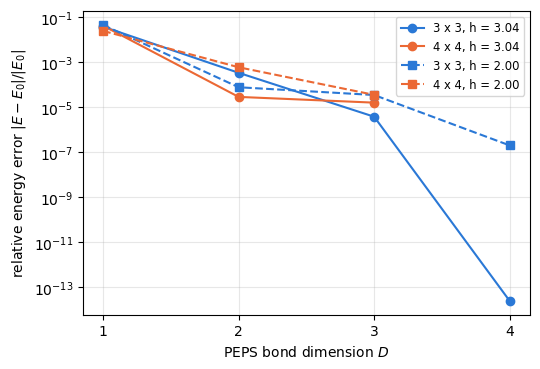

In [17]:
colors = {3: "#2a78d6", 4: "#eb6834"}
markers = {3.04: "o", 2.0: "s"}
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for (h_, L), res in results.items():
    Ds = list(res.keys())
    errors = [abs(res[D]["E"] - exact[(h_, L)]) / abs(exact[(h_, L)]) for D in Ds]
    ax.semilogy(Ds, errors, marker=markers[h_], color=colors[L], linestyle="-" if h_ == 3.04 else "--",
                label="%d x %d, h = %.2f" % (L, L, h_))
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("PEPS bond dimension $D$")
ax.set_ylabel(r"relative energy error $|E - E_0| / |E_0|$")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize="small")
plt.tight_layout()
plt.show()

**Observations.**
* $D = 1$ is the mean-field product state, with relative errors of 2–4 %. Already $D = 2$ reduces the error to between $3 \times 10^{-5}$ and $6 \times 10^{-4}$.
* On $3 \times 3$ at $h = 3.04$, the error drops to $4 \times 10^{-6}$ for $D = 3$, and $D = 4$ reproduces the exact ground state to machine precision ($2 \times 10^{-14}$); at $h = 2$, the $D = 4$ run reaches $2 \times 10^{-7}$.
* On $4 \times 4$, $D = 3$ gains only little over $D = 2$ ($1.6 \times 10^{-5}$ vs. $2.8 \times 10^{-5}$ at $h = 3.04$). Most runs stop at `maxsweeps` = 30 while the energy is still decreasing slowly: the site-by-site optimization converges slowly, and different seeds end in different local minima.
* The norm deviation is at the level of rounding errors ($\lesssim 10^{-10}$) everywhere, as it should be for exact boundaries; the GEP energy agrees with the independently measured energy.

### Dependence on the boundary bond dimension $\chi$
On the $4 \times 4$ lattice with $D = 3$, exact boundaries need $\chi = 81$. We take the state optimized with $\chi = 81$ and look at two effects of a smaller $\chi$:
1. **Evaluation:** the energy of this state, measured with $\chi$, and the norm deviation as an estimate of the error.
2. **Optimization:** we continue the optimization with $\chi$ (at most 10 sweeps, with the acceptance check) and measure the result exactly. We also record the lowest GEP energy during these sweeps: with truncated boundaries it lies below the exact ground state energy $E_0$, which shows how the update exploits the truncation errors.

In [18]:
L, D = 4, 3
terms = ising_terms(L, L, J, 3.04)
E0 = exact[(3.04, L)]
reference = results[(3.04, L)][D]["peps"]
chis = [3, 6, 9, 18, 27, 36, 54, 81]

evaluation = {chi: measure(reference, terms, chi) for chi in chis}
optimization = {}
for chi in [9, 18, 27, 36, 54]:
    peps = copy_peps(reference)
    info = optimize(peps, terms, chi, maxsweeps=10)
    gep = [e for e in info["gep"] if e == e]   # without NaN (sites where no direction was kept)
    optimization[chi] = dict(E_exact=measure(peps, terms, 81)[0], E_chi=info["energies"][-1], E_gep=min(gep),
                             sweeps=len(info["runtimes"]), stop=info["stop"])

for chi in chis:
    E, deviation = evaluation[chi]
    line = "chi = %2d: evaluation: relative error %.1e, norm deviation %.0e" % (chi, abs(E - E0) / abs(E0), deviation)
    if chi in optimization:
        o = optimization[chi]
        line += (" | optimization (%d sweeps, %s): exact %.1e, lowest GEP energy %.1e"
                 % (o["sweeps"], o["stop"], abs(o["E_exact"] - E0) / abs(E0), (o["E_gep"] - E0) / abs(E0)))
    print(line)

chi =  3: evaluation: relative error 4.7e-01, norm deviation 1e+00
chi =  6: evaluation: relative error 9.6e-04, norm deviation 2e-01
chi =  9: evaluation: relative error 4.6e-04, norm deviation 1e-01 | optimization (1 sweeps, energy increased): exact 1.6e-05, lowest GEP energy -8.6e-02
chi = 18: evaluation: relative error 1.4e-04, norm deviation 5e-03 | optimization (1 sweeps, energy increased): exact 1.6e-05, lowest GEP energy -2.0e+00
chi = 27: evaluation: relative error 9.5e-05, norm deviation 5e-03 | optimization (1 sweeps, energy increased): exact 1.6e-05, lowest GEP energy -1.3e-01
chi = 36: evaluation: relative error 2.2e-05, norm deviation 1e-03 | optimization (1 sweeps, energy increased): exact 1.6e-05, lowest GEP energy -2.0e+00
chi = 54: evaluation: relative error 2.0e-05, norm deviation 1e-04 | optimization (1 sweeps, energy increased): exact 1.6e-05, lowest GEP energy 1.1e-05
chi = 81: evaluation: relative error 1.6e-05, norm deviation 1e-14


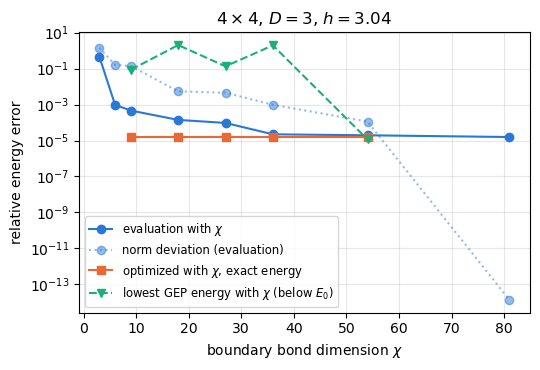

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.semilogy(chis, [abs(evaluation[chi][0] - E0) / abs(E0) for chi in chis], "o-", color="#2a78d6",
            label=r"evaluation with $\chi$")
ax.semilogy(chis, [evaluation[chi][1] for chi in chis], "o:", color="#2a78d6", alpha=0.5,
            label=r"norm deviation (evaluation)")
opt = sorted(optimization)
ax.semilogy(opt, [abs(optimization[chi]["E_exact"] - E0) / abs(E0) for chi in opt], "s-", color="#eb6834",
            label=r"optimized with $\chi$, exact energy")
ax.semilogy(opt, [abs(optimization[chi]["E_gep"] - E0) / abs(E0) for chi in opt], "v--", color="#1baf7a",
            label=r"lowest GEP energy with $\chi$ (below $E_0$)")
ax.set_xlabel(r"boundary bond dimension $\chi$")
ax.set_ylabel("relative energy error")
ax.set_title(r"$4 \times 4$, $D = 3$, $h = 3.04$")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize="small")
plt.tight_layout()
plt.show()

**Observations.**
* **Evaluation:** with truncated boundaries, the energy of a fixed state converges quickly in $\chi$: the error is $10^{-3}$ at $\chi = 6$ and reaches the level of the PEPS error ($2 \times 10^{-5}$) at $\chi \approx 36$–$54$. The norm deviation decreases together with the error and is an upper estimate of it here (it is larger than the energy error by one to two orders of magnitude), cf. [dissertation, sec. 4.4.3].
* **Optimization:** in every case, already the first sweep with truncated boundaries *increases* the measured energy, so the acceptance check returns to the initial state (flat orange curve). During this sweep, the GEP finds "energies" far below the exact ground state energy (green: up to twice $|E_0|$ below for $\chi \le 36$; for $\chi = 54$ the lowest GEP energy is $10^{-5}$ above $E_0$, but the measured energy still increases). The update exploits the truncation errors: the boundaries of the separate terms are truncated independently, so the errors of $H_\text{eff}$ and $N_\text{eff}$ do not cancel, and the reduction to the standard eigenvalue problem amplifies them by $1/n$ in directions with small norm.
* Evaluating expectation values with $\chi \sim D^2$ is fine; **optimizing** with the separate-term boundaries needs (nearly) exact boundaries. Section 8 makes truncated boundaries usable with a damped update and a larger cutoff of the GEP. Consistent truncation of all boundaries (e.g. accumulated Hamiltonian boundaries that share the truncation of the norm) and gauge fixing of the bonds would address the cause directly.

### Dependence on the system size
The energy per site $E/V$ for $V = L \times L$ with $L = 3, \dots, 6$, for $D = 2$ and $D = 3$ (up to $L = 5$), with exact boundaries, compared with exact diagonalization where possible. For the larger lattices we use a single seed and fewer sweeps for $D = 3$, to keep the runtime in minutes ($5 \times 5$ with $D = 3$ and $\chi = 81$ takes about 25 s per sweep).

In [20]:
sizes = {3: results[(3.04, 3)], 4: results[(3.04, 4)]}
for L, Ds, maxsweeps in [(5, [1, 2, 3], {1: 30, 2: 30, 3: 10}), (6, [1, 2], 30)]:
    start = time.perf_counter()
    sizes[L] = grow_and_optimize(L, L, ising_terms(L, L, J, 3.04), Ds, chi_of_D=exact_chi(L), seeds=(1,),
                                 maxsweeps=maxsweeps)
    print("%d x %d: %.0f s" % (L, L, time.perf_counter() - start))
for L, res in sizes.items():
    for D in [2, 3]:
        if D in res:
            r = res[D]
            print("   L = %d, D = %d, chi = %2d: E/V = %.8f, norm deviation %.0e, %2d sweeps (%s), %.0f s"
                  % (L, D, r["chi"], r["E"] / L**2, r["deviation"], r["sweeps"], r["info"]["stop"], r["runtime"]))

5 x 5: 371 s


6 x 6: 218 s
   L = 3, D = 2, chi =  4: E/V = -3.15649849, norm deviation 2e-15, 30 sweeps (maxsweeps), 5 s
   L = 3, D = 3, chi =  9: E/V = -3.15753199, norm deviation 4e-15, 30 sweeps (maxsweeps), 11 s
   L = 4, D = 2, chi = 16: E/V = -3.17440026, norm deviation 1e-12, 30 sweeps (maxsweeps), 21 s
   L = 4, D = 3, chi = 81: E/V = -3.17443997, norm deviation 1e-14, 30 sweeps (maxsweeps), 68 s
   L = 5, D = 2, chi = 16: E/V = -3.18376806, norm deviation 9e-13, 30 sweeps (maxsweeps), 61 s
   L = 5, D = 3, chi = 81: E/V = -3.18454979, norm deviation 2e-14, 10 sweeps (maxsweeps), 290 s
   L = 6, D = 2, chi = 64: E/V = -3.18962045, norm deviation 1e-10, 30 sweeps (maxsweeps), 179 s


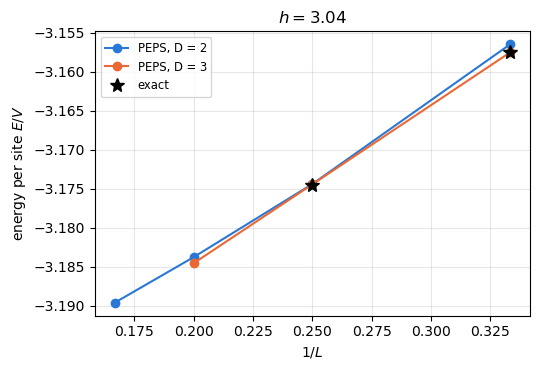

In [21]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for D, color in [(2, "#2a78d6"), (3, "#eb6834")]:
    Ls = [L for L in sizes if D in sizes[L]]
    ax.plot([1 / L for L in Ls], [sizes[L][D]["E"] / L**2 for L in Ls], "o-", color=color, label="PEPS, D = %d" % D)
ax.plot([1 / L for L in [3, 4]], [exact[(3.04, L)] / L**2 for L in [3, 4]], "k*", markersize=10, label="exact")
ax.set_xlabel("$1/L$")
ax.set_ylabel("energy per site $E/V$")
ax.set_title("$h = 3.04$")
ax.grid(True, alpha=0.3)
ax.legend(fontsize="small")
plt.tight_layout()
plt.show()

**Observations.**
* The energy per site decreases with the system size, because the fraction of sites at the open boundary (with fewer bonds) decreases. $E/V$ is close to linear in $1/L$, as expected for boundary effects $\propto L / L^2$.
* Where exact results exist ($L = 3, 4$), the PEPS energies agree with them to $10^{-5}$ (the stars lie on top of the PEPS points). For larger $L$, the difference between $D = 2$ and $D = 3$ grows (relative $2.5 \times 10^{-4}$ for $5 \times 5$), since the correlations near the critical point extend over more sites. The $5 \times 5$, $D = 3$ point is not fully converged (10 sweeps).
* Runtimes per optimization with exact boundaries: about 1 minute for $5 \times 5$ with $D = 2$ ($\chi = 16$), 3 minutes for $6 \times 6$ with $D = 2$ ($\chi = 64$) and 5 minutes for 10 sweeps of $5 \times 5$ with $D = 3$ ($\chi = 81$). Exact boundaries become infeasible for larger lattices ($\chi = D^{2 \lfloor L/2 \rfloor}$ grows exponentially with $L$), which is where stable truncated boundaries are needed.

## 8. Damped updates
Section 7 showed that the optimization fails with truncated boundaries, although energies *measured* with the same $\chi$ are accurate. The GEP finds the exact minimum of the local energy
$$
E(A) = \frac{A^\dagger H_\text{eff} A}{A^\dagger N_\text{eff} A},
$$
but with truncated boundaries this minimum lies in directions in which $H_\text{eff}$ and $N_\text{eff}$ are wrong, far away from the current tensor. Close to the current tensor the local energy is accurate: the boundaries were computed for the current state. This suggests smaller steps: instead of replacing the tensor by the GEP solution $\tilde A$, we take a superposition of the old and the new tensor.

### Literature
* **Corboz** [PRB 94, 035133 (2016), sec. III] solves the same GEP for iPEPS. Replacing the tensor by $\tilde A$ is not necessarily the best update, because $H_\text{eff}$ and $N_\text{eff}$ depend on the tensor themselves; instead he uses $A'(\lambda) = \tilde A \sin(\lambda\pi) - A \cos(\lambda\pi)$ with $\lambda \in [0.5, 1.5]$ ($\lambda = 1$ is the old tensor, $\lambda = 0.5$ the GEP solution). $\lambda$ is chosen by a simple line search: if $E(0.5) < E(1)$, $\tilde A$ is accepted; otherwise steps $\Delta = 0.1$ away from $\lambda = 1$ in the downhill direction are tried and halved until the energy decreases. Every energy evaluation needs recomputed environments. "Pathological" trial states, for which the environment does not converge or the norm becomes very small, are rejected.
* **Vanderstraeten, Haegeman, Corboz & Verstraete** [PRB 94, 155123 (2016)] replace the GEP by a conjugate gradient method with a line search (bisection with an Armijo condition). They point out that optimizing the tensors of a finite PEPS one after the other is "severely hampered by the bad conditioning", because the energy and the norm require different effective environments, and that the regularization of the bad condition number is not well defined. This is exactly the problem of section 7.
* **Lubasch, Cirac & Bañuls** [NJP 16, 033014 (2014)] replace the norm matrices by their closest Hermitian approximant, invert them with a pseudo-inverse with a cutoff, and fix the gauge of the bonds; without gauge fixing they observed instabilities, especially with rough environment approximations.

### Adaptation to finite PEPS
**Mixture.** Let $a = A / \|A\|_N$ and $b = \tilde A / \|\tilde A\|_N$ be normalized with the effective norm, $\|A\|_N^2 = A^\dagger N_\text{eff} A$, so that both describe states with norm 1, and choose the phase of $b$ (for real tensors its sign) such that $c = a^\dagger N_\text{eff}\, b > 0$. The new tensor is
$$
A' = (1 - \alpha)\, a + \alpha\, b, \qquad 0 < \alpha \le 1 .
$$
For orthogonal $a$ and $b$, this moves along the same arc as Corboz's $A'(\lambda)$, up to the normalization. The phase makes $A'$ move towards $\tilde A$ on the shorter way: since $H_\text{eff}\, b = \tilde E\, N_\text{eff}\, b$, the slope of the local energy is
$$
\frac{d E(A')}{d\alpha}\Big|_{\alpha = 0} = 2 c\, (\tilde E - E) < 0 ,
$$
and in the plane spanned by $a$ and $b$ the local energy decreases monotonically from $\alpha = 0$ to $\alpha = 1$.

**Step size.** Corboz's line search optimizes a single tensor. A finite PEPS has $V$ different tensors, and an independent energy evaluation needs new boundaries for the whole lattice, so a line search at every site would cost about $V$ times more. We therefore use the same $\alpha$ for all site updates of a sweep and adapt it by backtracking between sweeps, based on the energy measured after the sweep: if it decreased, the sweep is accepted and $\alpha$ is doubled (up to 1); otherwise the sweep is discarded and $\alpha$ is halved. This extends the acceptance check of section 6, which could only stop.

**Cutoff of the GEP.** The reduction to the standard eigenvalue problem amplifies the errors of $H_\text{eff}$ in the direction of an eigenvector of $N_\text{eff}$ with eigenvalue $n_i$ by $n_\text{max} / n_i$; once this factor exceeds the inverse relative accuracy of the boundaries, the direction carries no information. In test runs, the cutoff $\epsilon = 10^{-12}$ of the previous sections kept so many of these directions that damping alone helped only partly, while $\epsilon = 10^{-4}$ made the optimization stable but limited its accuracy (on $4 \times 4$ with $D = 3$ and exact boundaries, the relative error stalled at $6 \times 10^{-5}$ instead of $10^{-6}$). `optimize_damped` therefore lowers the cutoff in stages: it starts with $10^{-4}$ and continues with $10^{-6}$ once the first stage has converged or $\alpha$ has dropped below $\alpha_\text{min} = 10^{-2}$; each stage starts again with $\alpha = 0.5$.

**Acceptance.** As seen in section 7, for very small $\chi$ even the measured energy can be too low and the acceptance check can be fooled. `chi_measure` allows measuring with larger boundaries than those used in the optimization.

`damped_update` computes the mixture; `optimize_site` calls it for `alpha` < 1 and returns the local energy of the mixture instead of the GEP eigenvalue.

In [22]:
def damped_update(old, new, Hm, Nm, alpha):
    """Mixture (1 - alpha) old + alpha new of the old tensor and the GEP solution (vectors).

    Both are normalized with N_eff, so they describe states with the same norm, and the
    phase of `new` (for real tensors: its sign) is chosen such that the overlap
    <old|N_eff|new> is real and positive. Then the mixture moves from the old state towards
    the GEP solution on the shorter way, and the energy of the local problem decreases
    monotonically with alpha. Returns the mixture and its energy in the local problem."""
    H, N = hermitian(Hm), hermitian(Nm)
    def braket(a, M, b):
        return cytnx.linalg.Vectordot(a, cytnx.linalg.Dot(M, b), True).item()
    norm_old, norm_new = braket(old, N, old).real, braket(new, N, new).real
    if norm_old <= 0 or norm_new <= 0:   # the environment cannot measure the old state
        return new, braket(new, H, new).real / norm_new
    s = braket(old, N, new)
    if abs(s) > 0:
        new = new * (abs(s) / s)
    mix = (1 - alpha) / math.sqrt(norm_old) * old + alpha / math.sqrt(norm_new) * new
    return mix, braket(mix, H, mix).real / braket(mix, N, mix).real

def optimize_damped(peps, terms, chi, cutoffs=(1e-4, 1e-6), alpha=0.5, alpha_min=1e-2, maxsweeps=30, tol=1e-8,
                    fit=None, chi_measure=None, verbose=False):
    """Variational ground state search with damped updates.

    Every site update replaces the tensor by the mixture of the old tensor and the GEP
    solution with weight alpha (damped_update). alpha is adapted from sweep to sweep by
    backtracking, the line search of [Corboz, PRB 94, 035133 (2016)] applied to whole
    sweeps: after every sweep the energy is measured independently, with boundaries of bond
    dimension chi_measure (default chi). If it decreased, the sweep is accepted and alpha is
    doubled (at most 1); otherwise the sweep is discarded and alpha is halved.

    The cutoff of the GEP is lowered in stages, one stage per entry of `cutoffs`. A stage
    ends when alpha < alpha_min, when an accepted sweep lowers the energy by at most tol
    (relative), or after maxsweeps sweeps (accepted or not); the next stage starts again
    with the initial alpha.
    Returns a dictionary with the measured energy, norm deviation, alpha, cutoff and
    acceptance of every sweep, the local energies after every site update, the runtimes,
    the energies of the initial and the final state and the reasons to stop. The PEPS ends
    in the best state."""
    fit = fit or {}
    chi_measure = chi_measure or chi
    cache = {}
    keys = ["energies", "deviations", "alphas", "cutoffs", "accepted", "runtimes"]
    info = {key: [] for key in keys}
    info.update(gep=[], stop=[])
    start = time.perf_counter()
    E_best, deviation = measure(peps, terms, chi_measure, fit)
    info["E_start"] = E_best
    best = copy_peps(peps)
    n = 0   # number of sweeps, for the alternating direction
    for cutoff in cutoffs:
        a = alpha
        stop = "maxsweeps"
        for _ in range(maxsweeps):
            direction = "down" if n % 2 == 0 else "up"
            n += 1
            trial = copy_peps(best)
            info["gep"] += sweep(trial, terms, chi, direction, cache, fit, cutoff, a)
            E, deviation = measure(trial, terms, chi_measure, fit)
            accepted = E < E_best
            for key, value in zip(keys, [E, deviation, a, cutoff, accepted, time.perf_counter() - start]):
                info[key].append(value)
            if verbose:
                print(f"  sweep {n - 1} ({direction}, cutoff {cutoff:.0e}, alpha = {a:.3g}): E = {E:.10f}, "
                      f"norm deviation {deviation:.1e}, {'accepted' if accepted else 'rejected'}, "
                      f"{info['runtimes'][-1]:.1f} s", flush=True)
            if accepted:
                converged = E_best - E <= tol * abs(E)
                E_best, best = E, trial
                a = min(1.0, 2 * a)
                if converged:
                    stop = "converged"
                    break
            else:
                a /= 2
                if a < alpha_min:
                    stop = "alpha < alpha_min"
                    break
        info["stop"].append(stop)
    peps.A, peps.bra_cache = best.A, {}
    info["E"] = E_best
    return info

**Tests** on a $3 \times 3$ lattice with exact boundaries ($\chi = 16$ for $D = 2$):
1. After one damped site update, the local energy of the mixture must equal the energy of the new state, both with boundary MPS and with the full state vector.
2. With exact boundaries, the local energy decreases monotonically also with damping.

In [23]:
L, chi = 3, 16
terms = ising_terms(L, L, J, h)
peps = random_peps(L, L, 2, seed=5)
cache = {}
tops = all_boundaries(peps, terms, chi, "top", cache, {})
bottoms = all_boundaries(peps, terms, chi, "bottom", cache, {})
norm, strips = row_strips(peps, terms, 1, tops[1], bottoms[1])
E_local, kept = optimize_site(peps, 1, 1, norm, strips, 1e-12, alpha=0.3)
print("site (1,1), alpha = 0.3: E(local) = %.12f, E(boundary MPS) = %.12f, E(state vector) = %.12f"
      % (E_local, measure(peps, terms, chi)[0], dense_energy(peps_to_state(peps), L, L, terms)))

peps = random_peps(L, L, 2, seed=7)
info = optimize_damped(peps, terms, chi, cutoffs=(1e-12,), alpha=0.25, maxsweeps=6, tol=0, verbose=True)
print("local energy decreases monotonically:", all(b <= a + 1e-10 for a, b in zip(info["gep"], info["gep"][1:])))

site (1,1), alpha = 0.3: E(local) = -2.499158054068, E(boundary MPS) = -2.499158054068, E(state vector) = -2.499158054068
  sweep 0 (down, cutoff 1e-12, alpha = 0.25): E = -21.2588495027, norm deviation 2.1e-15, accepted, 0.2 s


  sweep 1 (up, cutoff 1e-12, alpha = 0.5): E = -27.5677890343, norm deviation 0.0e+00, accepted, 0.4 s


  sweep 2 (down, cutoff 1e-12, alpha = 1): E = -28.2113315151, norm deviation 1.0e-15, accepted, 0.5 s


  sweep 3 (up, cutoff 1e-12, alpha = 1): E = -28.2862030730, norm deviation 1.0e-15, accepted, 0.7 s


  sweep 4 (down, cutoff 1e-12, alpha = 1): E = -28.3251344122, norm deviation 1.0e-15, accepted, 0.8 s


  sweep 5 (up, cutoff 1e-12, alpha = 1): E = -28.3500709902, norm deviation 1.0e-15, accepted, 1.0 s


local energy decreases monotonically: True


### Optimization with truncated boundaries
We repeat the growth step from $D = 2$ to $D = 3$ on the $4 \times 4$ lattice at $h = 3.04$, now with truncated boundaries. The starting point is the optimized $D = 2$ state of section 7, embedded in $D = 3$ tensors with noise $10^{-2}$; its relative energy error is $8 \times 10^{-2}$. We compare the plain update (`optimize`: the GEP solution replaces the tensor, stop at the first increase of the energy; for several cutoffs, one call per cutoff) with the damped update (`optimize_damped`), each with the cutoff $10^{-12}$ of the previous sections and with the cutoff stages $10^{-4}$, $10^{-6}$:
* $\chi = 18 = 2 D^2$: all four combinations,
* $\chi = 9 = D^2$: plain and damped with the cutoff stages, and damped with the acceptance measured with $\chi = 18$.

The final states are evaluated with exact boundaries ($\chi = 81$). For comparison: the $D = 2$ state has a relative error of $2.8 \times 10^{-5}$, the $D = 3$ optimization with exact boundaries in section 7 reached $1.6 \times 10^{-5}$. The runs take about 6 minutes.

In [24]:
L, D = 4, 3
terms = ising_terms(L, L, J, 3.04)
E0 = exact[(3.04, L)]
start_peps = grow_bond_dimension(results[(3.04, L)][2]["peps"], D, noise=1e-2, seed=1)

def run(chi, damped, cutoffs, chi_measure=None):
    # Optimize a copy of start_peps. Returns the lowest measured energy as a function of the
    # runtime, the energy of the final state with exact boundaries, the number of sweeps and the runtime.
    peps = copy_peps(start_peps)
    if damped:
        info = optimize_damped(peps, terms, chi, cutoffs=cutoffs, chi_measure=chi_measure)
        times, energies = [0.0] + info["runtimes"], [info["E_start"]] + info["energies"]
        sweeps, runtime = len(info["energies"]), info["runtimes"][-1]
    else:
        times, energies, sweeps, runtime = [0.0], [measure(peps, terms, chi)[0]], 0, 0.0
        for cutoff in cutoffs:   # each call stops at the first sweep that increases the energy
            info = optimize(peps, terms, chi, maxsweeps=30, cutoff=cutoff)
            times += [runtime + t for t in info["runtimes"][:len(info["energies"])]]
            energies += info["energies"]
            sweeps, runtime = sweeps + len(info["runtimes"]), runtime + info["runtimes"][-1]
    lowest = [min(energies[:i + 1]) for i in range(len(energies))]
    times, lowest = times + [runtime], lowest + [lowest[-1]]   # rejected sweeps at the end of the run
    return dict(times=times, lowest=lowest, E_exact=measure(peps, terms, 81)[0], sweeps=sweeps, runtime=runtime)

stages = (1e-4, 1e-6)
cases = [   # chi, label, damped, cutoffs, chi_measure, color, line style
    (18, "plain, cutoff 1e-12", False, (1e-12,), None, "#2a78d6", "--"),
    (18, "damped, cutoff 1e-12", True, (1e-12,), None, "#2a78d6", "-"),
    (18, "plain, cutoff 1e-4, 1e-6", False, stages, None, "#eb6834", "--"),
    (18, "damped, cutoff 1e-4, 1e-6", True, stages, None, "#eb6834", "-"),
    (9, "plain, cutoff 1e-4, 1e-6", False, stages, None, "#eb6834", "--"),
    (9, "damped, cutoff 1e-4, 1e-6", True, stages, None, "#eb6834", "-"),
    (9, "damped, cutoff 1e-4, 1e-6, acceptance with chi = 18", True, stages, 18, "#1baf7a", "-"),
]
damped_runs = {}
for chi, label, damped, cutoffs, chi_measure, color, style in cases:
    damped_runs[(chi, label)] = run(chi, damped, cutoffs, chi_measure)
    r = damped_runs[(chi, label)]
    print("chi = %2d, %-52s relative error %.1e (exact boundaries), %2d sweeps, %4.0f s"
          % (chi, label + ":", abs(r["E_exact"] - E0) / abs(E0), r["sweeps"], r["runtime"]), flush=True)

chi = 18, plain, cutoff 1e-12:                                 relative error 7.7e-02 (exact boundaries),  1 sweeps,    3 s


chi = 18, damped, cutoff 1e-12:                                relative error 8.8e-03 (exact boundaries), 12 sweeps,   24 s


chi = 18, plain, cutoff 1e-4, 1e-6:                            relative error 4.7e-06 (exact boundaries), 17 sweeps,   30 s


chi = 18, damped, cutoff 1e-4, 1e-6:                           relative error 3.9e-06 (exact boundaries), 52 sweeps,   86 s


chi =  9, plain, cutoff 1e-4, 1e-6:                            relative error 4.4e-03 (exact boundaries),  3 sweeps,    5 s


chi =  9, damped, cutoff 1e-4, 1e-6:                           relative error 6.5e-04 (exact boundaries), 29 sweeps,   46 s


chi =  9, damped, cutoff 1e-4, 1e-6, acceptance with chi = 18: relative error 4.3e-05 (exact boundaries), 48 sweeps,   74 s


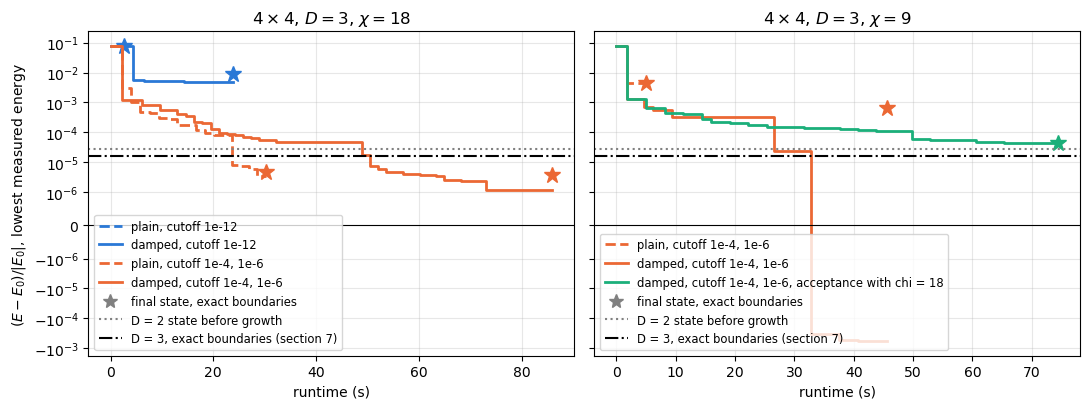

In [25]:
rel = lambda E: (E - E0) / abs(E0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, chi in zip(axes, [18, 9]):
    for c, label, damped, cutoffs, chi_measure, color, style in cases:
        if c == chi:
            r = damped_runs[(c, label)]
            ax.plot(r["times"], [rel(E) for E in r["lowest"]], drawstyle="steps-post", color=color, linestyle=style,
                    linewidth=2, label=label)
            ax.plot(r["times"][-1], rel(r["E_exact"]), marker="*", markersize=12, color=color, linestyle="none")
    ax.plot([], [], marker="*", markersize=10, color="gray", linestyle="none", label="final state, exact boundaries")
    ax.axhline(rel(results[(3.04, L)][2]["E"]), color="gray", linestyle=":", label="D = 2 state before growth")
    ax.axhline(rel(results[(3.04, L)][3]["E"]), color="black", linestyle="-.", label="D = 3, exact boundaries (section 7)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_yscale("symlog", linthresh=1e-6)
    ax.set_xlabel("runtime (s)")
    ax.set_title(r"$4 \times 4$, $D = 3$, $\chi = %d$" % chi)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize="small")
axes[0].set_ylabel(r"$(E - E_0) / |E_0|$, lowest measured energy")
plt.tight_layout()
plt.show()

**Observations.** Lines show the lowest energy measured during the optimization (with the boundaries of the acceptance check), stars the energy of the final state with exact boundaries; the vertical axis is linear between $\pm 10^{-6}$ and logarithmic outside, so that energies below $E_0$ remain visible.
* **Damping alone is not enough.** With the cutoff $10^{-12}$, the plain update stops after the first sweep (the energy increased; the dashed blue line ends at the start value), as in section 7. The damped update keeps lowering the energy, but $\alpha$ drops below $10^{-2}$ within 12 sweeps and the error stalls at $9 \times 10^{-3}$: the GEP solution points mostly into directions in which the boundaries are wrong, and only a small part of each step is a real improvement.
* **The cutoff is the main cure.** With the cutoff stages $10^{-4}$, $10^{-6}$, already the plain update is stable for $\chi = 18$ and reaches a relative error of $4.7 \times 10^{-6}$ in about half a minute, better than the optimization with exact boundaries in section 7 ($1.6 \times 10^{-5}$ in about 2 minutes, from a noisier start). The damped update reaches $3.9 \times 10^{-6}$, but takes three times longer, because about half of its sweeps are rejected while $\alpha$ is probed. In test runs with $\chi = 36$ the picture was the same ($2.2 \times 10^{-6}$ plain, $1.3 \times 10^{-6}$ damped).
* **Damping matters at small $\chi$.** For $\chi = 9 = D^2$, the plain update collapses in the second sweep even with the cutoff stages and returns the state after the first sweep ($4.4 \times 10^{-3}$). The damped update stays stable and reaches $6.5 \times 10^{-4}$, but its measured energy drops below $E_0$: with $\chi = 9$, the acceptance check itself is fooled and accepts sweeps that make the state worse. Measuring the energy for the acceptance with $\chi = 18$ fixes this; the error decreases steadily to $4.3 \times 10^{-5}$. This is still above the $D = 2$ state ($2.8 \times 10^{-5}$): with $\chi = D^2$ the boundaries are too poor to profit from $D = 3$ on this lattice.
* **Larger lattices.** In a separate run (not part of this notebook), we used `optimize_damped` with the cutoff stages on the $6 \times 6$ lattice, where exact boundaries for $D = 3$ would need $\chi = 729$. Starting from the $D = 2$ state of section 7 ($E/V = -3.18962$, grown with noise $10^{-2}$), 50 sweeps with $\chi = 36$ gave $E/V = -3.192157$ for $D = 3$ (about 50 minutes); measured with $\chi = 81$, the energy agrees to $10^{-9}$. With $\chi = 18$, the result measured with $\chi = 81$ was $E/V = -3.192137$.
* In practice: use the cutoff stages always, the damped update as a safeguard, and for $\chi \lesssim D^2$ an acceptance measurement with larger boundaries.

## Summary and outlook
* We implemented the variational optimization of finite PEPS with boundary MPS for the transverse field Ising model, keeping the Hamiltonian as a list of separate terms: every term gets its own boundary MPS, and $H_\text{eff} = \sum_t H_\text{eff}^{(t)}$.
* The generalized eigenvalue problem is solved by diagonalizing the norm, dropping its unreliable part (eigenvalues below $10^{-12}\, n_\text{max}$ or below the size of a negative eigenvalue) and solving the resulting Hermitian standard eigenvalue problem; Cytnx has no GEP solver.
* All building blocks are tested against exact contractions of the full state; the ground state energies agree with exact diagonalization to $10^{-5}$ for $D = 3$ and to machine precision for $3 \times 3$ with $D = 4$.
* **Pitfalls** that we met on the way:
  1. `Svd_truncate(T, keepdim, err)` compares the singular values with `err` in absolute terms; normalize the tensor first, or "exact" boundaries are silently truncated.
  2. With many small tensors, Cytnx should run with `OMP_NUM_THREADS=1` and `OMP_WAIT_POLICY=PASSIVE`; otherwise idle OpenMP threads busy-wait, and two runs in parallel slow each other down dramatically.
  3. With truncated boundaries and the cutoff $10^{-12}$, the optimization with separate terms is unstable: the GEP exploits the independent truncation errors of the terms in directions with a small norm. Check every sweep with an independent energy measurement, and with very small $\chi$ measure with larger boundaries, because the measured energy can drop below the ground state energy.
* **Damped updates** (section 8): mixing the old tensor and the GEP solution, with a step size adapted between sweeps, is the finite-PEPS version of the line search of Corboz (2016). Together with a larger cutoff of the GEP, lowered in stages ($10^{-4}$, then $10^{-6}$), the optimization with truncated boundaries becomes stable: on $4 \times 4$ with $D = 3$ and $\chi = 2D^2$, it reaches a relative error of $4 \times 10^{-6}$. The cutoff is the more important ingredient; damping alone is not enough, but it keeps the optimization stable at $\chi = D^2$, where the plain update collapses.
* **Next steps:** consistent truncation of all boundaries (accumulated Hamiltonian boundaries or shared projectors, which also reduces the cost from $\sim 2V$ boundaries per row to a constant factor), gauge fixing of the bonds with the positive part of the bond environment, a cutoff of the GEP tied to the accuracy of the boundaries (e.g. to the norm deviation) instead of fixed stages, symmetric tensors ($\mathbb{Z}_2$ parity of the Ising model), and larger lattices with truncated boundaries.